# Round 1/2: Data Understanding, Cleaning & EDA
ConnectSphere Telecom - Customer Churn Insight (U23AD491, SBA-2, Use Case 02)

In [1]:
import sys, matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")   # plain-script runs: save charts without opening Tk windows (fixes the tkinter error)
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt, os, warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True); os.makedirs("data", exist_ok=True)
RAW = "data/raw/"
cust = pd.read_csv(RAW + "customers.csv"); usage = pd.read_csv(RAW + "usage.csv")
bill = pd.read_csv(RAW + "billing.csv");   sup = pd.read_csv(RAW + "support.csv")
svc = pd.read_csv(RAW + "service.csv")

## 1. Understand the data: shape, types, missing, duplicates

In [2]:
files = {"customers": cust, "usage": usage, "billing": bill, "support": sup, "service": svc}
summary = pd.DataFrame({n: {"rows": d.shape[0], "cols": d.shape[1],
                            "missing_cells": int(d.isnull().sum().sum()),
                            "duplicate_rows": int(d.duplicated().sum())} for n, d in files.items()}).T
print(summary)
print("\nDuplicate customer IDs in customers.csv:", cust.customer_id.duplicated().sum())
print("\nRaw plan-name variants:", cust.plan.nunique()); print(cust.plan.value_counts().head(12))
print("\nBilling charges describe:\n", bill.charges.describe())
print("\nMissing per column (usage):\n", usage.isnull().sum())
print("\nCustomers with NO usage rows:", len(set(cust.customer_id) - set(usage.customer_id)))
print("Customers with NO support tickets:", len(set(cust.customer_id) - set(sup.customer_id)))

            rows  cols  missing_cells  duplicate_rows
customers   5150     8              0             150
usage      28800     5           2160               0
billing    30000     5              0               0
support     5355     6            536               0
service     4359     5              0               0

Duplicate customer IDs in customers.csv: 150

Raw plan-name variants: 34
plan
Prepaid Basic        900
Prepaid Plus         671
Postpaid Standard    652
Broadband Home       541
Postpaid Premium     365
prepaid basic        136
Prepaid-Basic        125
prepaid plus         123
postpaid standard    113
PREPAID BASIC        111
prepaid_basic        108
Prepaid-Plus          99
Name: count, dtype: int64

Billing charges describe:
 count    30000.000000
mean       673.676606
std       1118.176200
min        136.790000
25%        283.817500
50%        537.000000
75%        833.622500
max      35874.810000
Name: charges, dtype: float64

Missing per column (usage):
 custome

## 2. Cleaning

In [3]:
log = {}  # numbers to copy into the submission sheet
# 2.1 duplicate customer IDs
log["duplicate_ids_removed"] = int(cust.customer_id.duplicated().sum())
cust = cust.drop_duplicates("customer_id", keep="first").reset_index(drop=True)

# 2.2 plan-name standardisation
def std_plan(x):
    x = str(x).strip().lower().replace("-", " ").replace("_", " ")
    x = x.replace("pre paid", "prepaid").replace("post paid", "postpaid")
    return " ".join(w.capitalize() for w in x.split())
log["plan_variants_before"] = int(pd.read_csv(RAW + "customers.csv").plan.nunique())
cust["plan"] = cust["plan"].map(std_plan)
log["plan_names_after"] = int(cust.plan.nunique())
print(cust.plan.value_counts())

# 2.3 missing usage: count, then impute with plan-wise median + flag
log["usage_rows_missing_entirely"] = int(len(cust) * 6 - len(usage))
log["usage_blank_values"] = int(usage[["voice_minutes", "data_gb", "sms_count"]].isnull().sum().sum())
usage = usage.merge(cust[["customer_id", "plan"]], on="customer_id", how="left")
for c in ["voice_minutes", "data_gb", "sms_count"]:
    usage[c] = usage[c].fillna(usage.groupby("plan")[c].transform("median"))
usage = usage.drop(columns="plan")

# 2.4 extreme bill values: IQR capping
q1, q3 = bill.charges.quantile([.25, .75]); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
log["extreme_bills_capped"] = int(((bill.charges > hi) | (bill.charges < lo)).sum())
bill["charges"] = bill.charges.clip(lo, hi)
bill["late_flag"] = (bill.payment_status != "Paid").astype(int)

# 2.5 incomplete support history
log["support_resolution_missing"] = int(sup.resolution_time_hrs.isnull().sum())
sup["resolution_time_hrs"] = sup.resolution_time_hrs.fillna(sup.resolution_time_hrs.median())
sup["category"] = sup.category.fillna("Unknown")

plan
Prepaid Basic        1442
Prepaid Plus         1103
Postpaid Standard    1072
Broadband Home        795
Postpaid Premium      588
Name: count, dtype: int64


## 3. Combine at CUSTOMER level (aggregate first, then merge)

In [4]:
usage = usage.sort_values(["customer_id", "month"])
u = usage.groupby("customer_id").agg(avg_voice=("voice_minutes", "mean"), avg_data=("data_gb", "mean"),
                                     avg_sms=("sms_count", "mean"))
first3 = usage[usage.month <= "2025-03"].groupby("customer_id")[["voice_minutes", "data_gb"]].mean().add_suffix("_first3")
last3 = usage[usage.month > "2025-03"].groupby("customer_id")[["voice_minutes", "data_gb"]].mean().add_suffix("_last3")
b = bill.groupby("customer_id").agg(avg_bill=("charges", "mean"), late_payments=("late_flag", "sum"),
                                    avg_late_days=("late_days", "mean"))
s = sup.groupby("customer_id").agg(tickets=("ticket_id", "count"), avg_resolution_hrs=("resolution_time_hrs", "mean"))
v = svc.pivot_table(index="customer_id", columns="event_type", values="event_id", aggfunc="count", fill_value=0)
v.columns = [c.lower().replace(" ", "_") + "s" for c in v.columns]       # network_issues, outages, plan_changes

df = cust.copy()
for part in [u, first3, last3, b, s, v]:
    df = df.merge(part, on="customer_id", how="left")
df["usage_missing_flag"] = df.avg_voice.isnull().astype(int)
for c in ["avg_voice", "avg_data", "avg_sms"]:
    df[c] = df[c].fillna(df.groupby("plan")[c].transform("median"))
for c in ["voice_minutes_first3", "voice_minutes_last3", "data_gb_first3", "data_gb_last3"]:
    df[c] = df[c].fillna(df.groupby("plan")[c].transform("median"))
df["tickets"] = df.tickets.fillna(0).astype(int)
df["avg_resolution_hrs"] = df.avg_resolution_hrs.fillna(0)          # no tickets -> 0 hrs
for c in ["network_issues", "outages", "plan_changes"]:
    df[c] = df[c].fillna(0).astype(int)
df["late_payments"] = df.late_payments.fillna(0).astype(int)
df["churn_flag"] = (df.churn == "Yes").astype(int)
log["final_rows"], log["final_cols"] = df.shape
df.to_csv("data/cleaned_churn_data.csv", index=False)      # DELIVERABLE 1
print("Cleaned dataset:", df.shape, "| remaining missing:", int(df.isnull().sum().sum()))

Cleaned dataset: (5000, 25) | remaining missing: 0


## 4. EDA - the 6 analytical questions

Overall churn rate: 26.2%


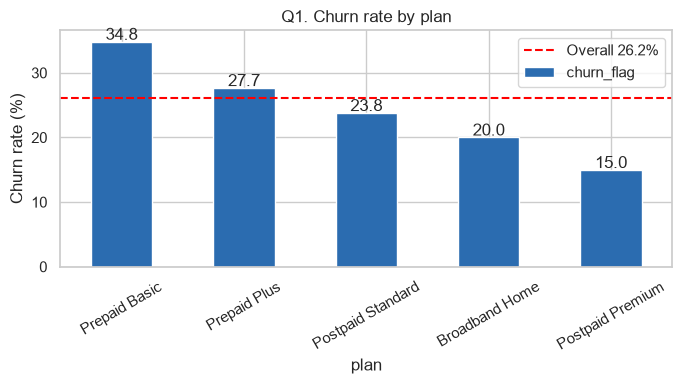

plan
Prepaid Basic        34.8
Prepaid Plus         27.7
Postpaid Standard    23.8
Broadband Home       20.0
Postpaid Premium     15.0
Name: churn_flag, dtype: float64


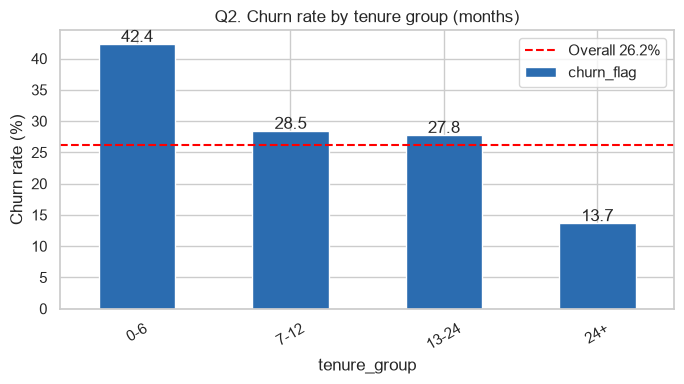

tenure_group
0-6      42.4
7-12     28.5
13-24    27.8
24+      13.7
Name: churn_flag, dtype: float64


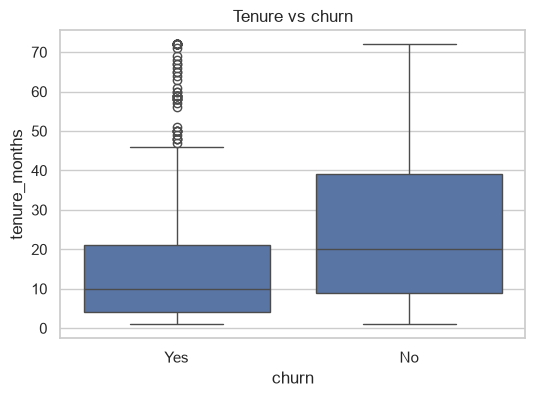

       tickets  avg_resolution_hrs
churn                             
No        0.81               23.46
Yes       1.82               45.66


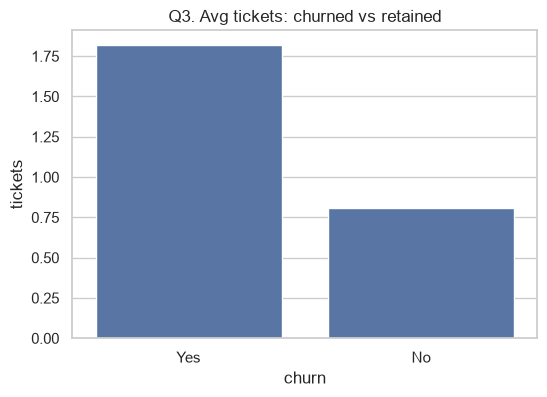

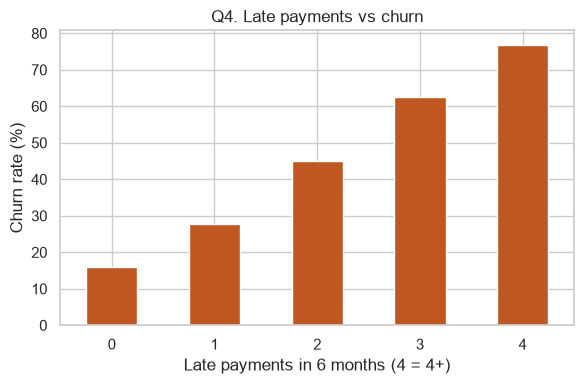

late_payments
0    16.1
1    27.8
2    44.9
3    62.7
4    76.9
Name: churn_flag, dtype: float64


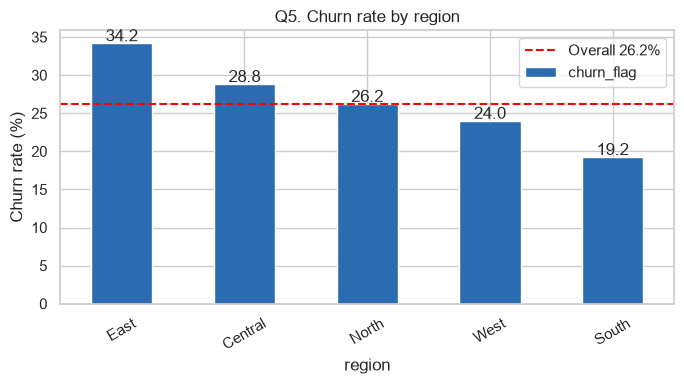

region
East       34.2
Central    28.8
North      26.2
West       24.0
South      19.2
Name: churn_flag, dtype: float64


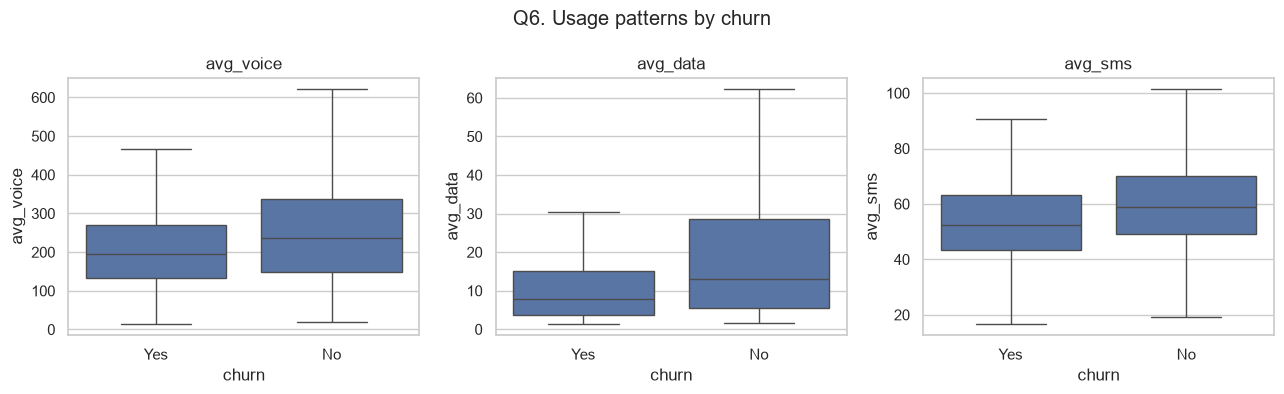

churn
No     0.010
Yes    0.143
Name: voice_drop, dtype: float64


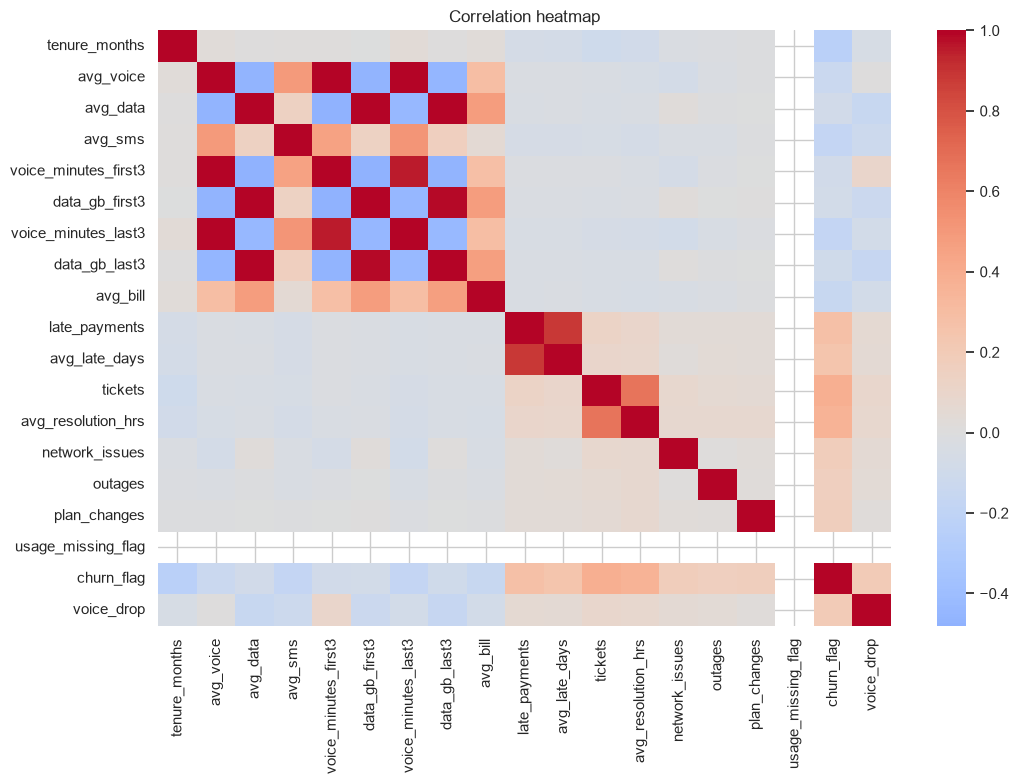

tickets                0.391
avg_resolution_hrs     0.366
late_payments          0.281
avg_late_days          0.245
tenure_months         -0.237
voice_drop             0.199
voice_minutes_last3   -0.179
network_issues         0.178
avg_sms               -0.174
plan_changes           0.168
Name: churn_flag, dtype: float64


In [5]:
df["tenure_group"] = pd.cut(df.tenure_months, [0, 6, 12, 24, 100], labels=["0-6", "7-12", "13-24", "24+"])
overall = df.churn_flag.mean()
print(f"Overall churn rate: {overall:.1%}")

def rate_plot(col, title, fname, order=None):
    r = df.groupby(col, observed=True).churn_flag.mean().mul(100)
    if order is None: r = r.sort_values(ascending=False)
    ax = r.plot(kind="bar", color="#2b6cb0", figsize=(7, 4), rot=30)
    ax.axhline(overall * 100, color="red", ls="--", label=f"Overall {overall:.1%}")
    ax.set_ylabel("Churn rate (%)"); ax.set_title(title); ax.legend()
    for i, val in enumerate(r): ax.text(i, val + .3, f"{val:.1f}", ha="center")
    plt.tight_layout(); plt.savefig(f"outputs/{fname}", dpi=130); plt.show()
    return r

# Q1 plans
q1_r = rate_plot("plan", "Q1. Churn rate by plan", "q1_churn_by_plan.png"); print(q1_r.round(1))
# Q2 tenure
q2_r = rate_plot("tenure_group", "Q2. Churn rate by tenure group (months)", "q2_churn_by_tenure.png", order=True); print(q2_r.round(1))
plt.figure(figsize=(6, 4)); sns.boxplot(data=df, x="churn", y="tenure_months"); plt.title("Tenure vs churn")
plt.savefig("outputs/q2_tenure_boxplot.png", dpi=130); plt.show()
# Q3 complaints
print(df.groupby("churn")[["tickets", "avg_resolution_hrs"]].mean().round(2))
plt.figure(figsize=(6, 4)); sns.barplot(data=df, x="churn", y="tickets", errorbar=None); plt.title("Q3. Avg tickets: churned vs retained")
plt.savefig("outputs/q3_tickets_vs_churn.png", dpi=130); plt.show()
# Q4 late payments
q4_r = df.groupby(df.late_payments.clip(upper=4)).churn_flag.mean().mul(100)
q4_r.plot(kind="bar", color="#c05621", figsize=(6, 4), rot=0); plt.xlabel("Late payments in 6 months (4 = 4+)")
plt.ylabel("Churn rate (%)"); plt.title("Q4. Late payments vs churn"); plt.tight_layout()
plt.savefig("outputs/q4_late_vs_churn.png", dpi=130); plt.show(); print(q4_r.round(1))
# Q5 region
q5_r = rate_plot("region", "Q5. Churn rate by region", "q5_churn_by_region.png"); print(q5_r.round(1))
# Q6 usage / disengagement
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, c in zip(ax, ["avg_voice", "avg_data", "avg_sms"]):
    sns.boxplot(data=df, x="churn", y=c, ax=a, showfliers=False); a.set_title(c)
plt.suptitle("Q6. Usage patterns by churn"); plt.tight_layout(); plt.savefig("outputs/q6_usage_vs_churn.png", dpi=130); plt.show()
df["voice_drop"] = 1 - df.voice_minutes_last3 / df.voice_minutes_first3.replace(0, np.nan)
print(df.groupby("churn").voice_drop.mean().round(3))

# heatmap
num = df.select_dtypes("number").drop(columns=["age"]).corr()
plt.figure(figsize=(11, 8)); sns.heatmap(num, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation heatmap"); plt.tight_layout(); plt.savefig("outputs/correlation_heatmap.png", dpi=130); plt.show()
print(num["churn_flag"].drop("churn_flag").sort_values(key=abs, ascending=False).round(3).head(10))

In [6]:
import json
log["overall_churn_rate_pct"] = round(overall * 100, 1)
json.dump(log, open("outputs/cleaning_log.json", "w"), indent=2)
print(json.dumps(log, indent=2))

{
  "duplicate_ids_removed": 150,
  "plan_variants_before": 34,
  "plan_names_after": 5,
  "usage_rows_missing_entirely": 1200,
  "usage_blank_values": 2160,
  "extreme_bills_capped": 182,
  "support_resolution_missing": 375,
  "final_rows": 5000,
  "final_cols": 25,
  "overall_churn_rate_pct": 26.2
}


# Round 2: Feature Engineering, Selection, ML Model and Intelligence Layer

In [7]:
import sys, matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")   # plain-script runs: save charts without opening Tk windows (fixes the tkinter error)
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, json, warnings
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
df = pd.read_csv("data/cleaned_churn_data.csv")

## 1. Feature engineering

In [8]:
df["tenure_group"] = pd.cut(df.tenure_months, [0, 6, 12, 24, 100], labels=["0-6", "7-12", "13-24", "24+"]).astype(str)
df["late_payment_ratio"] = df.late_payments / 6
df["tickets_per_month"] = df.tickets / df.tenure_months.clip(upper=6)
df["total_usage"] = df.avg_voice / 100 + df.avg_data + df.avg_sms / 50
df["voice_drop"] = (1 - df.voice_minutes_last3 / df.voice_minutes_first3.replace(0, np.nan)).fillna(0).clip(-1, 1)
df["data_drop"] = (1 - df.data_gb_last3 / df.data_gb_first3.replace(0, np.nan)).fillna(0).clip(-1, 1)
df["usage_drop"] = (df.voice_drop + df.data_drop) / 2
df["bill_per_usage"] = df.avg_bill / (df.total_usage + 1)
df["high_complaint_flag"] = (df.tickets >= 3).astype(int)
df["service_issues"] = df.network_issues + df.outages
df["ticket_group"] = pd.cut(df.tickets, [-1, 0, 2, 100], labels=["0", "1-2", "3+"]).astype(str)
df["payment_behaviour"] = pd.cut(df.late_payments, [-1, 0, 1, 100], labels=["On-time", "1 late", "2+ late"]).astype(str)

## 2. Encoding

In [9]:
y = df.churn_flag
cat_cols = ["plan", "region", "gender"]
num_cols = ["tenure_months", "age", "avg_voice", "avg_data", "avg_sms", "avg_bill", "late_payments",
            "avg_late_days", "tickets", "avg_resolution_hrs", "network_issues", "outages", "plan_changes",
            "late_payment_ratio", "tickets_per_month", "total_usage", "usage_drop", "bill_per_usage",
            "high_complaint_flag", "service_issues"]
X_all = pd.concat([df[num_cols], pd.get_dummies(df[cat_cols], drop_first=True, dtype=int)], axis=1)
print("Features before selection:", X_all.shape[1])

Features before selection: 30


## 3. Feature selection (correlation filter + Random Forest importance)

Dropped (corr > 0.90 with another feature): ['late_payment_ratio', 'total_usage']


Selected 18 features:
 usage_drop             0.152
avg_resolution_hrs     0.125
tenure_months          0.074
tickets_per_month      0.065
avg_data               0.058
avg_voice              0.053
avg_bill               0.053
bill_per_usage         0.052
avg_late_days          0.049
avg_sms                0.048
age                    0.042
tickets                0.039
late_payments          0.036
service_issues         0.030
high_complaint_flag    0.021
plan_changes           0.018
network_issues         0.014
outages                0.013
dtype: float64


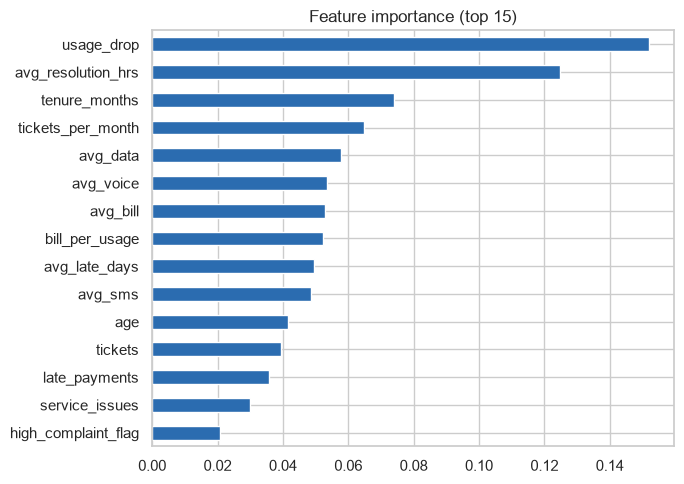

PCA: 12 components explain 95% variance out of 18


In [10]:
corr = X_all.corr().abs(); upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
drop_corr = [c for c in upper.columns if any(upper[c] > 0.90)]
print("Dropped (corr > 0.90 with another feature):", drop_corr)
X_f = X_all.drop(columns=drop_corr)
rf_sel = RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced", n_jobs=-1).fit(X_f, y)
imp = pd.Series(rf_sel.feature_importances_, index=X_f.columns).sort_values(ascending=False)
selected = imp[imp >= 0.01].index.tolist()
print(f"Selected {len(selected)} features:\n", imp.loc[selected].round(3))
imp.head(15).sort_values().plot(kind="barh", figsize=(7, 5), color="#2b6cb0"); plt.title("Feature importance (top 15)")
plt.tight_layout(); plt.savefig("outputs/feature_importance.png", dpi=130); plt.show()

# optional PCA (information only)
from sklearn.decomposition import PCA
Xs = StandardScaler().fit_transform(X_f[selected]); pca = PCA().fit(Xs)
n95 = int(np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.95) + 1)
print(f"PCA: {n95} components explain 95% variance out of {len(selected)}")

## 4. Model training and evaluation

           Random Forest  Logistic Regression (baseline)
Accuracy           0.839                           0.803
Precision          0.671                           0.596
Recall             0.756                           0.771
F1                 0.711                           0.672
ROC_AUC            0.891                           0.881


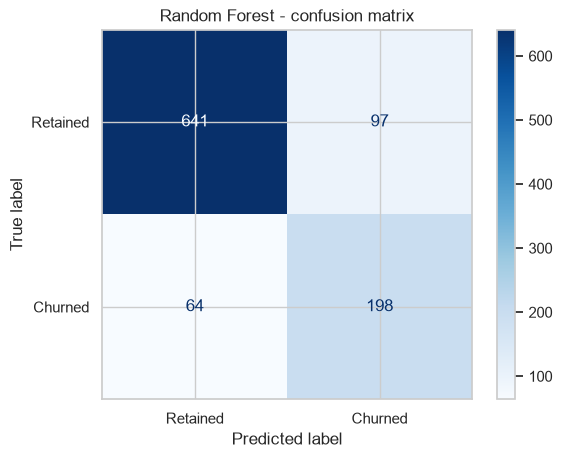

In [11]:
X = X_f[selected]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
rf = RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=5,
                            class_weight="balanced", random_state=42, n_jobs=-1).fit(X_tr, y_tr)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")).fit(X_tr, y_tr)

def metrics(m):
    p = m.predict(X_te); pr = m.predict_proba(X_te)[:, 1]
    return dict(Accuracy=accuracy_score(y_te, p), Precision=precision_score(y_te, p),
                Recall=recall_score(y_te, p), F1=f1_score(y_te, p), ROC_AUC=roc_auc_score(y_te, pr))
res = pd.DataFrame({"Random Forest": metrics(rf), "Logistic Regression (baseline)": metrics(lr)}).round(3)
print(res)
ConfusionMatrixDisplay(confusion_matrix(y_te, rf.predict(X_te)), display_labels=["Retained", "Churned"]).plot(cmap="Blues")
plt.title("Random Forest - confusion matrix"); plt.savefig("outputs/confusion_matrix.png", dpi=130); plt.show()
cv = cross_val_predict(rf, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42), method="predict_proba")[:, 1]

## 5. Intelligence layer: churn-risk score, segments and retention actions

In [12]:
df["risk_score"] = cv.round(3)          # out-of-fold probability (no leakage)
df["risk_level"] = pd.cut(df.risk_score, [-0.01, 0.4, 0.7, 1.0], labels=["Low", "Medium", "High"]).astype(str)

def segment(r):
    if r.usage_drop >= 0.25: return "Disengaged Low-Usage"
    if r.late_payments >= 2: return "Payment-Risk"
    if r.tickets >= 3 or r.outages >= 2: return "Service-Unhappy"
    if r.tenure_months <= 12: return "New Customer"
    return "Loyal Stable"
df["segment"] = df.apply(segment, axis=1)

ACTION = {"Disengaged Low-Usage": "Personalised data/voice bonus pack + re-engagement call",
          "Payment-Risk": "Flexible due date, auto-pay incentive, SMS reminder",
          "Service-Unhappy": "Priority complaint resolution + network-credit / goodwill discount",
          "New Customer": "Onboarding journey + first-year loyalty offer",
          "Loyal Stable": "Reward / upsell, no urgent action"}
df["retention_action"] = df.segment.map(ACTION)
print(df.groupby("segment").agg(customers=("customer_id", "count"), churn_rate=("churn_flag", "mean"),
                                avg_risk=("risk_score", "mean")).round(3))
print(df.risk_level.value_counts())
df.to_csv("data/churn_featured_data.csv", index=False)                       # used by Excel
df[["customer_id", "plan", "region", "risk_score", "risk_level", "segment", "retention_action"]] \
  .sort_values("risk_score", ascending=False).to_csv("outputs/churn_risk_scores.csv", index=False)

out = {"selected_features": selected, "n_features_before_selection": int(X_all.shape[1]),
       "n_selected": len(selected), "pca_components_95pct": n95, "dropped_corr": drop_corr,
       "metrics": res.to_dict(), "high_risk_customers": int((df.risk_level == "High").sum()),
       "train_size": len(X_tr), "test_size": len(X_te)}
json.dump(out, open("outputs/model_results.json", "w"), indent=2)
print(json.dumps(out["metrics"], indent=2))

                      customers  churn_rate  avg_risk
segment                                              
Disengaged Low-Usage        791       0.604     0.689
Loyal Stable               1973       0.090     0.196
New Customer               1159       0.166     0.299
Payment-Risk                699       0.391     0.488
Service-Unhappy             378       0.497     0.598
risk_level
Low       3148
Medium     971
High       881
Name: count, dtype: int64


{
  "Random Forest": {
    "Accuracy": 0.839,
    "Precision": 0.671,
    "Recall": 0.756,
    "F1": 0.711,
    "ROC_AUC": 0.891
  },
  "Logistic Regression (baseline)": {
    "Accuracy": 0.803,
    "Precision": 0.596,
    "Recall": 0.771,
    "F1": 0.672,
    "ROC_AUC": 0.881
  }
}
